# SMS Spam Detector: Deep Learning Under a Leak-Free Evaluation

This notebook is the analysis behind the [SMS Spam Detector app](https://sms-spam-detector-cnoret.streamlit.app/). It explores the UCI SMS Spam Collection, shows why the first evaluation of the project overstated its scores, and studies the neural network the app serves (word embeddings + a character-level CNN) against a TF-IDF + logistic regression baseline.

Training lives in [`train.py`](../train.py), which writes the models and [`models/metrics.json`](../models/metrics.json). The notebook imports the same functions, so the data loading, the split and the threshold rule are written once. It reads the committed models instead of retraining them, and checks that it finds the same test scores as `metrics.json`.

**Contents**
1. Setup
2. The data
3. Exploratory analysis
4. Why the first evaluation leaked
5. Evaluation protocol
6. The neural network
7. Results on the held-out test set
8. Is the gap with the baseline real?
9. Error analysis
10. Try your own SMS
11. Conclusion

## 1. Setup

On Colab, the cell clones the repository and installs the training requirements (about a minute). Locally, run it from the repository with `pip install -r requirements-train.txt` done.

In [1]:
import os
import sys
from pathlib import Path

if "google.colab" in sys.modules and not Path("train.py").exists():
    !git clone -q https://github.com/cnoret/sms-spam-detector.git
    %cd sms-spam-detector
    %pip install -q -r requirements-train.txt

# Work from the repository root, whether the notebook is opened from notebook/ or the root.
if not Path("train.py").exists() and Path("../train.py").exists():
    os.chdir("..")
sys.path.insert(0, os.getcwd())
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"  # keep TensorFlow start-up logs out of the outputs
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"  # same numbers on every CPU


In [2]:
import html
import json
import re
from collections import Counter

import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from sklearn.metrics import f1_score, precision_recall_curve
from sklearn.model_selection import StratifiedKFold, train_test_split
from wordcloud import WordCloud

import train as T

pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
HAM, SPAM = "#4C72B0", "#C44E52"
print("Keras", keras.__version__)

Keras 3.12.4


## 2. The data

The raw file has 5,572 rows. A few hundred messages contain commas that pushed part of the text into extra unnamed columns: `train.load_data` glues them back together before anything else.

In [3]:
raw = pd.read_csv(T.DATA_PATH, encoding="latin-1")
print(raw.shape)
raw.head()

(5572, 5)


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives around here though",NaN,NaN,NaN


In [4]:
text_cols = [c for c in raw.columns if c != "v1"]
full = pd.DataFrame({
    "message": raw[text_cols].fillna("").agg(" ".join, axis=1).str.strip(),
    "label": raw["v1"].map({"ham": 0, "spam": 1}),
})
print(f"Messages split over extra columns: {raw[text_cols[1:]].notna().any(axis=1).sum()}")
print(f"Exact duplicate messages: {full.message.duplicated().sum()} rows")
print(f"Unique messages: {full.message.nunique()}")

df = T.load_data()  # rebuilt and deduplicated, as every model sees it
assert len(df) == full.message.nunique()

Messages split over extra columns: 50
Exact duplicate messages: 414 rows
Unique messages: 5158


In [5]:
dup = full[full.message.duplicated(keep=False)]
(dup.groupby("message").agg(copies=("label", "size"), spam=("label", "max"))
    .sort_values("copies", ascending=False).head(8))

,copies,spam
message,,
"Sorry, I'll call later",30,0
I cant pick the phone right now. Pls send a message,12,0
Ok...,10,0
"Wen ur lovable bcums angry wid u, dnt take it seriously.. Coz being angry is d most childish n true way of showing deep affection, care n luv!.. kettoda manda... Have nice day da.",4,0
Your opinion about me? 1. Over 2. Jada 3. Kusruthi 4. Lovable 5. Silent 6. Spl character 7. Not matured 8. Stylish 9. Simple Pls reply..,4,0
Please call our customer service representative on FREEPHONE 0808 145 4742 between 9am-11pm as you have WON a guaranteed å£1000 cash or å£5000 prize!,4,1
Ok.,4,0
"Say this slowly.? GOD,I LOVE YOU &amp; I NEED YOU,CLEAN MY HEART WITH YOUR BLOOD.Send this to Ten special people &amp; u c miracle tomorrow, do it,pls,pls do it...",4,0


Duplicates are mostly stock replies (`Sorry, I'll call later` appears 30 times) and spam campaigns sent several times. Left in, they end up on both sides of a random split, see section 4.

## 3. Exploratory analysis

On the 5,158 unique messages.

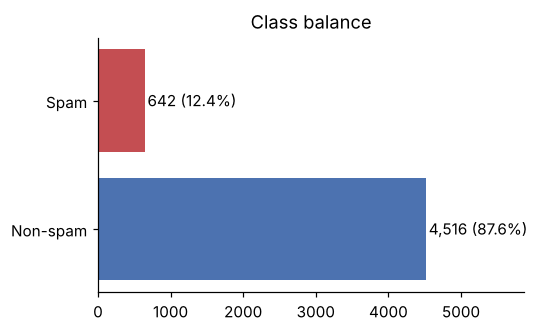

In [6]:
counts = df.label.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(5, 3))
ax.barh(["Non-spam", "Spam"], counts.values, color=[HAM, SPAM])
for i, v in enumerate(counts.values):
    ax.text(v + 40, i, f"{v:,} ({v / len(df):.1%})", va="center")
ax.set_xlim(0, counts.max() * 1.3)
ax.set_title("Class balance")
plt.show()

**Imbalance**: 12.4% spam. A model that always answers "non-spam" reaches 87.6% accuracy, so accuracy says little here. Models are compared on spam precision, recall and F1, and trained with balanced class weights.

           count   mean   std   min    25%    50%    75%    max
label                                                          
non-spam  4516.0   71.0  57.0   2.0   34.0   53.0   92.0  910.0
spam       642.0  138.0  30.0  13.0  132.0  148.0  157.0  224.0


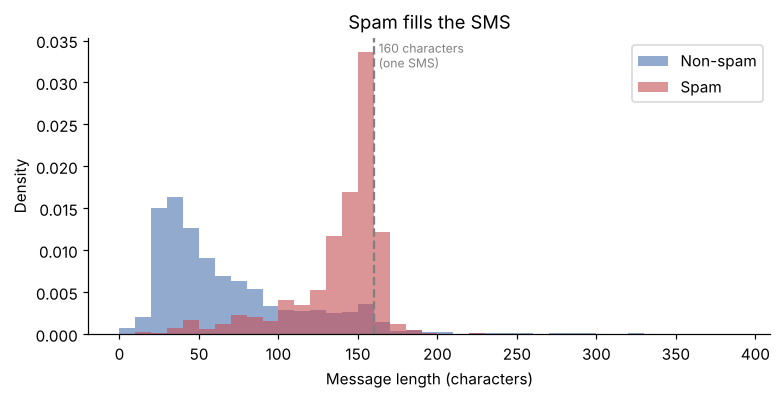

In [7]:
df["length"] = df.message.str.len()
print(df.groupby("label").length.describe().rename(index={0: "non-spam", 1: "spam"}).round(0))

fig, ax = plt.subplots(figsize=(8, 3.5))
bins = np.arange(0, 400, 10)
ax.hist(df.loc[df.label == 0, "length"], bins=bins, alpha=0.6, density=True, color=HAM, label="Non-spam")
ax.hist(df.loc[df.label == 1, "length"], bins=bins, alpha=0.6, density=True, color=SPAM, label="Spam")
ax.axvline(160, ls="--", c="grey")
ax.text(163, ax.get_ylim()[1] * 0.9, "160 characters\n(one SMS)", color="grey", fontsize=8)
ax.set(xlabel="Message length (characters)", ylabel="Density", title="Spam fills the SMS")
ax.legend()
plt.show()

**Length**: spam is nearly twice as long (median about 150 characters against about 50) and piles up just under the 160-character limit of a single SMS: senders pack the whole offer into one message.

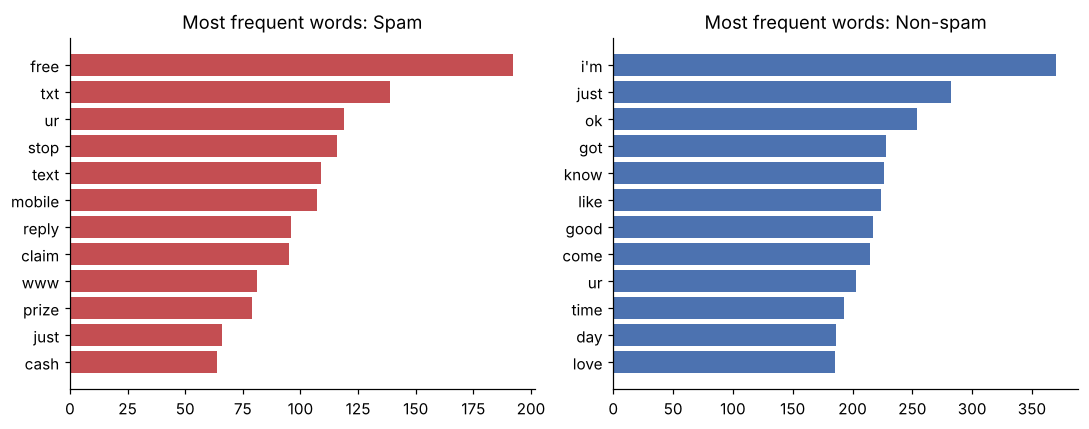

In [8]:
def words(text):
    text = html.unescape(text).replace("<#>", " ")  # "&lt;#&gt;" is a placeholder left by anonymisation
    return [w for w in re.findall(r"[a-z']+", text.lower()) if w not in ENGLISH_STOP_WORDS and len(w) > 1]

spam_words = Counter(w for m in df.message[df.label == 1] for w in words(m))
ham_words = Counter(w for m in df.message[df.label == 0] for w in words(m))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, freq, color, title in [(axes[0], spam_words, SPAM, "Spam"), (axes[1], ham_words, HAM, "Non-spam")]:
    top = pd.Series(dict(freq.most_common(12))).sort_values()
    ax.barh(top.index, top.values, color=color)
    ax.set_title(f"Most frequent words: {title}")
plt.tight_layout()
plt.show()

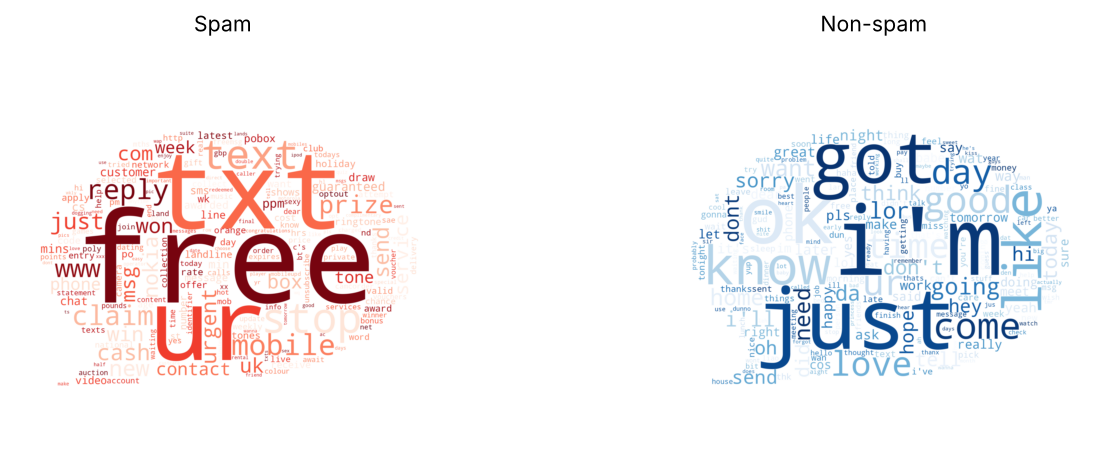

In [9]:
from PIL import Image

mask = np.array(Image.open("img/cloudmask.png"))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, freq, cmap, title in [(axes[0], spam_words, "Reds", "Spam"), (axes[1], ham_words, "Blues", "Non-spam")]:
    cloud = WordCloud(background_color="white", colormap=cmap, mask=mask, random_state=0)
    ax.imshow(cloud.generate_from_frequencies(freq), interpolation="bilinear")
    ax.set_title(title, fontsize=14)
    ax.axis("off")
plt.show()

**Vocabulary**: spam speaks of rewards and urgency (`free`, `txt`, `claim`, `prize`, `mobile`, `reply`, `stop`), everyday messages of plans and replies (`ok`, `got`, `know`, `come`, `good`). Spam also carries tokens a word tokenizer handles badly:

In [10]:
patterns = {
    "Phone number (10+ digits)": r"\d{10,}",
    "Short code (5 digits)": r"\b\d{5}\b",
    "Currency sign (£ $ €)": r"[£$€]",
    "Web address": r"www\.|http|\.com",
}
pd.DataFrame({
    name: df.groupby("label").message.apply(lambda s, p=p: s.str.contains(p).mean())
    for name, p in patterns.items()
}).T.rename(columns={0: "non-spam", 1: "spam"}).style.format("{:.1%}")

label,non-spam,spam
Phone number (10+ digits),0.0%,54.2%
Short code (5 digits),0.0%,31.8%
Currency sign (£ $ €),0.4%,33.3%
Web address,0.2%,15.7%


Phone numbers, short codes and currency signs are close to spam-only signals, and they are made of digits and symbols that a word vocabulary either drops or scatters into rare tokens. This is the reason for the character branch of the network (section 6).

## 4. Why the first evaluation leaked

The first version of this notebook split the raw file (duplicates included) at random, and reported spam F1 0.89. Here is the same split:

In [11]:
raw_train, raw_test = train_test_split(full, test_size=0.2, random_state=42)
seen = raw_test.message.isin(set(raw_train.message))
print(f"Test messages also present in the train set: {seen.sum()} of {len(raw_test)} ({seen.mean():.1%})")
print(f"Among test spams: {seen[raw_test.label == 1].sum()} of {(raw_test.label == 1).sum()}")

Test messages also present in the train set: 132 of 1115 (11.8%)
Among test spams: 34 of 150


Almost 12% of the test messages, and more than one test spam in five, were already in the training data. A model scores well on those by memory, not by generalising, so the score overstated what the model would do on new messages. On top of that, the deployed app skipped the spaCy cleaning used in training, which brought its real spam precision down to 0.54.

Both issues are fixed in `train.py`, and the original architecture is retrained under the new protocol as a reference: spam F1 **0.856** on unseen messages.

## 5. Evaluation protocol

Shared by every model:

- **Deduplicate before splitting**, so that no test message was seen in training.
- **One stratified 80/20 split** (seed 42): 4,126 messages to train, 1,032 to test. The test set is used once, at the end.
- **Every choice is made on the train set**: architecture, vocabulary, number of epochs, decision threshold, with 5-fold cross-validation.
- **Decision threshold**: the lowest one whose spam precision reaches 98% on out-of-fold predictions. Blocking a legitimate SMS costs more than letting a spam through, so precision is fixed first and recall maximised under it.

In [12]:
train, test = train_test_split(df, test_size=0.2, stratify=df.label, random_state=T.SEED)
metrics = json.loads(T.METRICS_PATH.read_text(encoding="utf-8"))

assert (len(train), len(test)) == (metrics["data"]["train"], metrics["data"]["test"])
pd.DataFrame({
    "messages": [len(train), len(test)],
    "spams": [train.label.sum(), test.label.sum()],
    "spam share": [f"{train.label.mean():.1%}", f"{test.label.mean():.1%}"],
}, index=["train", "test"])

,messages,spams,spam share
train,4126,514,12.5%
test,1032,128,12.4%


## 6. The neural network

```text
raw SMS ─┬─ word vectorizer (10k words, 64 tokens) → embedding 64 → global max pooling ──┐
         └─ character vectorizer (300 chars) → embedding 32 → Conv1D 128×5 → max pooling ─┴─ concat → dropout 0.3 → dense 32 → sigmoid
```

- The **word branch** learns the vocabulary of spam. Global max pooling keeps the strongest signal of each embedding dimension, so one `prize` in a long message is enough.
- The **character branch** reads spellings that a word tokenizer loses: `£1000`, `txt`, `08712...`, short codes. A 5-character convolution is a learned detector of character 5-grams.
- Both `TextVectorization` layers are **inside the model**: they learn their vocabulary on the train set and are saved with the weights. The app sends the raw text, so training and serving cannot drift apart, which was the bug of the first version.

**Architecture selection.** Six candidates were compared on the train set only, with 5-fold cross-validation (spam F1 on out-of-fold predictions, at the 98% precision threshold):

| Candidate | CV spam F1 |
| --- | --- |
| Word embeddings + BiGRU | 0.901 |
| Character CNN + BiGRU | 0.880 |
| Character CNN, kernels 3/5/7 | 0.922 |
| Character CNN, kernel 5 | 0.932 |
| Word BiGRU + character CNN | 0.940 |
| **Word embeddings (max pooling) + character CNN** | **0.953** |
| TF-IDF + logistic regression (baseline) | 0.962 |

Recurrent layers did worse than pooling: SMS are short, and spam is recognised by a few telling tokens more than by word order.

In [13]:
network = keras.models.load_model(T.NETWORK_PATH)
network.summary()

Model: "word_char_cnn"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ message             │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_vectorization… │ (None, 300)       │          0 │ message[0][0]     │
│ (TextVectorization) │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_vectorization… │ (None, 64)        │          0 │ message[0][0]     │
│ (TextVectorization) │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_11        │ (None, 300, 32)   │      6,400 │ text_vectorizati… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_10        │ (None, 64, 64)    │    640,000 │ text_vectorizati… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_5 (Conv1D)   │ (None, 296, 128)  │     20,608 │ embedding_11[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 64)        │          0 │ embedding_10[0][… │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 128)       │          0 │ conv1d_5[0][0]    │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_5       │ (None, 192)       │          0 │ global_max_pooli… │
│ (Concatenate)       │                   │            │ global_max_pooli… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_5 (Dropout) │ (None, 192)       │          0 │ concatenate_5[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 32)        │      6,176 │ dropout_5[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spam_probability    │ (None, 1)         │         33 │ dense_5[0][0]     │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 673,217 (2.57 MB)

 Trainable params: 673,217 (2.57 MB)

 Non-trainable params: 0 (0.00 B)

### Learning curves

To show how training behaves, the cell below fits the same architecture on one fold of the train set (80% fit, 20% validation), as `train.py` does for each of its five folds. Nothing is saved, and the test set is not touched (about 30 seconds on CPU).

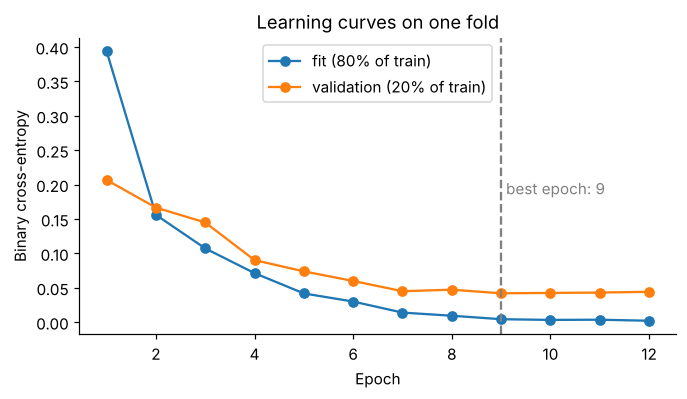

Validation spam F1 at 0.5: 0.951


In [14]:
keras.utils.set_random_seed(T.SEED)
x, y = train.message.to_numpy(dtype=object), train.label.to_numpy()
fit_idx, val_idx = next(StratifiedKFold(5, shuffle=True, random_state=T.SEED).split(x, y))

demo = T.build_network(x[fit_idx])
history = demo.fit(
    T._as_tensor(x[fit_idx]), y[fit_idx],
    validation_data=(T._as_tensor(x[val_idx]), y[val_idx]),
    epochs=T.MAX_EPOCHS, batch_size=32, class_weight=T._class_weight(y[fit_idx]),
    callbacks=[keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)],
    verbose=0,
)
loss, val_loss = history.history["loss"], history.history["val_loss"]
best = int(np.argmin(val_loss)) + 1

fig, ax = plt.subplots(figsize=(7, 3.5))
epochs = range(1, len(loss) + 1)
ax.plot(epochs, loss, marker="o", label="fit (80% of train)")
ax.plot(epochs, val_loss, marker="o", label="validation (20% of train)")
ax.axvline(best, ls="--", c="grey")
ax.text(best + 0.1, max(val_loss) * 0.9, f"best epoch: {best}", color="grey")
ax.set(xlabel="Epoch", ylabel="Binary cross-entropy", title="Learning curves on one fold")
ax.legend()
plt.show()

val_proba = T.network_proba(demo, x[val_idx])
print(f"Validation spam F1 at 0.5: {f1_score(y[val_idx], val_proba >= 0.5):.3f}")

The validation loss bottoms out after a handful of epochs, then the model starts to overfit the training messages: early stopping keeps the best weights. Over the five folds, `train.py` takes the median best epoch (**9**, recorded in `metrics.json`) to fit the final model on the whole train set.

## 7. Results on the held-out test set

The committed models are scored on the 1,032 test messages, at the thresholds `train.py` chose out of fold. The check at the end of the cell confirms they match `models/metrics.json`.

In [15]:
import joblib

baseline_bundle = joblib.load(T.MODEL_PATH)
baseline = baseline_bundle["pipeline"]

proba = {
    "network": T.network_proba(network, test.message),
    "baseline": baseline.predict_proba(test.message)[:, 1],
}
threshold = {k: metrics[k]["threshold"] for k in proba}
pred = {k: (proba[k] >= threshold[k]).astype(int) for k in proba}
y_test = test.label.to_numpy()

for k in proba:
    found = T.scores(y_test, pred[k])
    assert found["confusion_matrix"] == metrics[k]["test"]["confusion_matrix"], k

rows = {}
for key, label in [("network", "Word + character CNN (Keras)"),
                   ("baseline", "TF-IDF + logistic regression (baseline)"),
                   ("original_network", "First network: Embedding + Dense, spaCy")]:
    s = metrics[key]["test"]
    rows[label] = {"threshold": metrics[key]["threshold"], "precision": s["precision"], "recall": s["recall"],
                   "F1": s["f1"], "legit flagged": s["confusion_matrix"]["fp"], "spams missed": s["confusion_matrix"]["fn"]}
pd.DataFrame(rows).T.astype({"legit flagged": int, "spams missed": int})

,threshold,precision,recall,F1,legit flagged,spams missed
Word + character CNN (Keras),0.751,0.992,0.938,0.964,1,8
TF-IDF + logistic regression (baseline),0.481,0.984,0.961,0.972,2,5
"First network: Embedding + Dense, spaCy",0.868,0.970,0.766,0.856,3,30


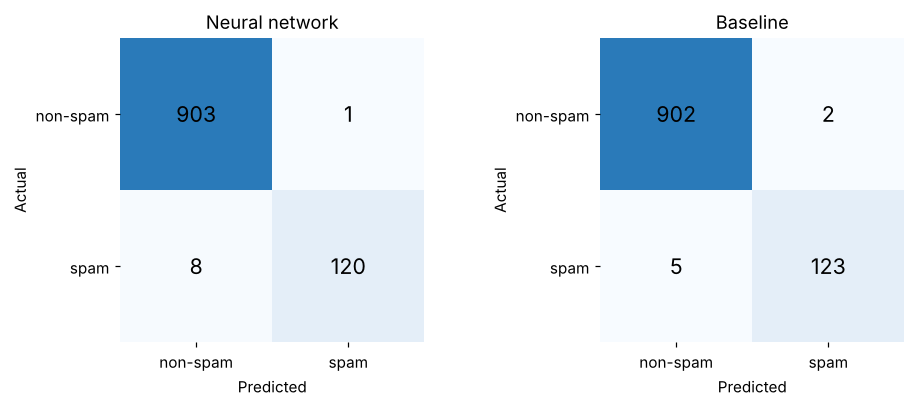

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, k, title in [(axes[0], "network", "Neural network"), (axes[1], "baseline", "Baseline")]:
    cm = metrics[k]["test"]["confusion_matrix"]
    grid = np.array([[cm["tn"], cm["fp"]], [cm["fn"], cm["tp"]]])
    ax.imshow(grid, cmap="Blues", vmax=grid.max() * 1.4)
    for (i, j), v in np.ndenumerate(grid):
        ax.text(j, i, v, ha="center", va="center", fontsize=14, color="black")
    ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["non-spam", "spam"], yticklabels=["non-spam", "spam"],
           xlabel="Predicted", ylabel="Actual", title=title)
    ax.spines[:].set_visible(False)
plt.tight_layout()
plt.show()

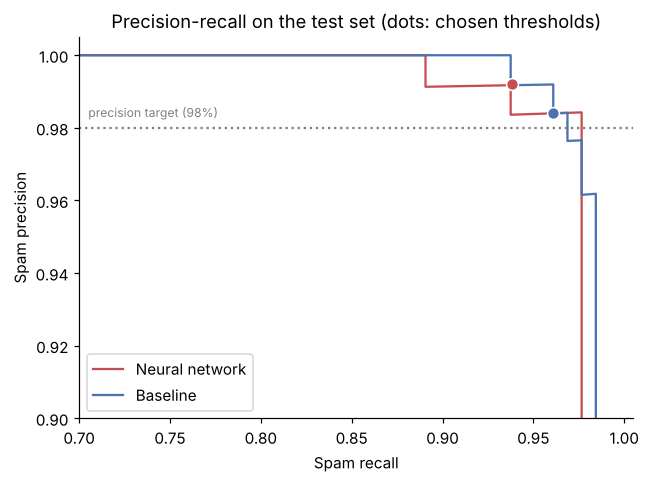

In [17]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for k, color, label in [("network", SPAM, "Neural network"), ("baseline", HAM, "Baseline")]:
    p, r, t = precision_recall_curve(y_test, proba[k])
    ax.plot(r, p, color=color, label=label)
    s = metrics[k]["test"]
    ax.scatter(s["recall"], s["precision"], color=color, s=60, zorder=3, edgecolor="white")
ax.axhline(metrics["min_precision_target"], ls=":", c="grey")
ax.text(0.705, metrics["min_precision_target"] + 0.003, "precision target (98%)", color="grey", fontsize=8)
ax.set(xlim=(0.7, 1.005), ylim=(0.9, 1.005), xlabel="Spam recall", ylabel="Spam precision",
       title="Precision-recall on the test set (dots: chosen thresholds)")
ax.legend(loc="lower left")
plt.show()

**Reading the results.** The redesigned network catches 22 more spams than the first version at the same precision target (120 against 98 of 128), with a single legitimate message flagged. Against the baseline, the two curves overlap over almost the whole range: the network flags one fewer legitimate message and misses three more spams.

## 8. Is the gap with the baseline real?

The test set has 128 spams, so a difference of a few messages may be noise. Two checks, on the same test messages:

- a **paired bootstrap**: resample the test set 5,000 times and look at the spread of the F1 difference,
- **McNemar's view**: only the messages where the two models disagree carry information about which is better.

In [18]:
rng = np.random.default_rng(T.SEED)
diffs = []
for _ in range(5000):
    i = rng.integers(0, len(y_test), len(y_test))
    diffs.append(f1_score(y_test[i], pred["network"][i]) - f1_score(y_test[i], pred["baseline"][i]))
low, high = np.percentile(diffs, [2.5, 97.5])
print(f"F1 network - baseline: {f1_score(y_test, pred['network']) - f1_score(y_test, pred['baseline']):+.3f}")
print(f"95% bootstrap interval: [{low:+.3f}, {high:+.3f}]")

net_ok, base_ok = pred["network"] == y_test, pred["baseline"] == y_test
print(f"\nOnly the network is right: {(net_ok & ~base_ok).sum()} messages")
print(f"Only the baseline is right: {(~net_ok & base_ok).sum()} messages")
print(f"Both wrong: {(~net_ok & ~base_ok).sum()} messages")

F1 network - baseline: -0.008
95% bootstrap interval: [-0.035, +0.017]

Only the network is right: 4 messages
Only the baseline is right: 6 messages
Both wrong: 3 messages


The interval runs from -0.035 to +0.017, so it contains zero, and the two models disagree on 10 messages out of 1,032: **on this data, the network and the baseline are tied**. The network is the heavier option to serve (TensorFlow, about 800 MB of memory against a few MB), which is the price of a model that learns its own text representation instead of relying on hand-chosen n-grams. The baseline stays in the app to keep that comparison visible.

## 9. Error analysis

What the network gets wrong, with both models' spam probabilities.

In [19]:
errors = test.assign(network=proba["network"].round(3), baseline=proba["baseline"].round(3))
errors = errors[pred["network"] != y_test].copy()
errors["error"] = np.where(errors.label == 1, "spam missed", "legit flagged")
errors["baseline right"] = (pred["baseline"] == y_test)[pred["network"] != y_test]
errors[["error", "message", "network", "baseline", "baseline right"]].sort_values(["error", "network"])

,error,message,network,baseline,baseline right
1250,legit flagged,"Hey...Great deal...Farm tour 9am to 5pm $95/pax, $50 deposit by 16 May",0.955,0.132,True
4978,spam missed,dating:i have had two of these. Only started after i sent a text to talk sport radio last week. Any connection do yo...,0.010,0.295,False
4604,spam missed,"Hi this is Amy, we will be sending you a free phone number in a couple of days, which will give you an access to all...",0.011,0.123,False
2298,spam missed,Babe: U want me dont u baby! Im nasty and have a thing 4 filthyguys. Fancy a rude time with a sexy bitch. How about ...,0.023,0.495,True
4429,spam missed,Cashbin.co.uk (Get lots of cash this weekend!) www.cashbin.co.uk Dear Welcome to the weekend We have got our biggest...,0.286,0.491,True
4018,spam missed,thesmszone.com lets you send free anonymous and masked messages..im sending this message from there..do you see the ...,0.294,0.516,True
1925,spam missed,TheMob>Yo yo yo-Here comes a new selection of hot downloads for our members to get for FREE! Just click & open the n...,0.490,0.858,True
2325,spam missed,Guess who am I?This is the first time I created a web page WWW.ASJESUS.COM read all I wrote. I'm waiting for your op...,0.625,0.358,False
1449,spam missed,"SMS. ac JSco: Energy is high, but u may not know where 2channel it. 2day ur leadership skills r strong. Psychic? Rep...",0.681,0.515,True


**Missed spams** are written like personal messages (a dating invitation, "Hi this is Amy...") or advertise a website instead of a phone number or a prize. They carry few of the digits and currency signs the character branch relies on. The baseline catches five of them, often just above its threshold, while the network catches four spams the baseline misses: the two models make different mistakes on the borderline cases, consistent with the tie in section 8.

**The one legitimate message flagged** is a friend forwarding a deal with prices (`$95/pax, $50 deposit`). The network gives it 0.96, the baseline 0.13: this is the cost of a character branch that has learnt that currency signs and numbers mean spam.

## 10. Try your own SMS

The messages from the app's examples, scored by both models. They are hand-written, so they illustrate rather than measure, and they include modern phishing (fake bank or account links) that the 2010s training data barely covers.

In [20]:
def score(messages):
    messages = list(messages)
    p_net = T.network_proba(network, messages)
    p_base = baseline.predict_proba(messages)[:, 1]
    return pd.DataFrame({
        "message": messages,
        "network": [f"{p:.0%} {'SPAM' if p >= threshold['network'] else ''}" for p in p_net],
        "baseline": [f"{p:.0%} {'SPAM' if p >= threshold['baseline'] else ''}" for p in p_base],
    })

examples = json.loads(Path("examples.json").read_text(encoding="utf-8"))
score(examples)

,message,network,baseline
0,Congratulations! You've won a free trip to Paris! Call now!,93% SPAM,80% SPAM
1,Reminder: Your appointment is scheduled for tomorrow at 10 am.,3%,22%
2,"Urgent! Your account will be locked, click here to verify: http://fakebank-secure-login.com",100% SPAM,68% SPAM
3,"Hey, wanna grab lunch today? Let me know!",0%,7%
4,You've won a $500 Walmart voucher! Click now: http://fakeurl.win,100% SPAM,79% SPAM
5,"Urgent: Your Netflix account will be locked, verify at http://netflix.verify-fake.com",100% SPAM,70% SPAM
6,"Hi there, just checking if you're free this weekend.",0%,8%
7,Final reminder: Pay your electricity bill to avoid disconnection.,6%,48% SPAM
8,You're selected for a free iPhone giveaway. Click now: http://freeiphone.click-here.fake,100% SPAM,72% SPAM
9,Meeting scheduled for tomorrow at 3 PM has been confirmed.,4%,8%


The network flags every phishing example here, the baseline all but the PayPal one, and the baseline also flags the electricity bill reminder (48%), a message that could well be legitimate. Edit the list below to try your own messages.

In [21]:
score(["Hey, are we still on for dinner tonight?",
       "WINNER!! Claim your £500 prize now, text WIN to 87121"])

,message,network,baseline
0,"Hey, are we still on for dinner tonight?",0%,9%
1,"WINNER!! Claim your £500 prize now, text WIN to 87121",100% SPAM,99% SPAM


## 11. Conclusion

- **Evaluation first.** 414 duplicate rows put almost 12% of the test messages of the first version in its training set, and a preprocessing mismatch broke the deployed app. Deduplicating before the split, choosing everything on the train set and keeping preprocessing inside the saved model fixed both.
- **The network.** Word embeddings plus a character CNN, chosen by cross-validation among six candidates, lift spam F1 from 0.856 to 0.964 on unseen messages, with one legitimate SMS flagged out of 904.
- **Against the baseline.** A TF-IDF + logistic regression on character n-grams reaches 0.972. The bootstrap shows the two are tied on this data, and they make different mistakes; the network learns its representation end to end, at a higher serving cost.
- **Limits.** About 5,000 English SMS from the early 2010s. Modern phishing is under-represented: the hand-written examples above are caught, but they are no measure of real-world traffic. This is a demonstration, not a production filter. Retraining on recent messages is the next step that would matter most.